# Sex-Specific Repeated-CV Comparison

Cox PH, tuned RSF, and tuned GBSA, each refit on 10 seeds x 5-fold CV within each sex separately, scored by C-index -- extending the classifiers' sex-specific protocol to the survival models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored
from sklearn.model_selection import StratifiedKFold
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
BASE = '../../'
USYD = ['#E64626', '#DAA8A2', '#71A399', '#8F9EC9', '#1A345E']

df = pd.read_csv(BASE + 'modeling_dataset.csv')
COMORBID_COLS = ['cat_Renal', 'cat_FluidElectrolyte', 'cat_Metabolic', 'cat_Respiratory',
                  'cat_MentalHealthSubstance', 'cat_Musculoskeletal', 'cat_Hematologic', 'cat_Hepatic',
                  'cat_Neurologic', 'cat_Oncologic', 'cat_EndocrineOther', 'cat_ConstitutionalFrailty']
UTILIZATION_COLS = ['baseline_n_diagnoses', 'baseline_n_procedures', 'baseline_n_claims',
                     'baseline_n_episodes', 'baseline_history_days']
COVARIATES = ['age'] + COMORBID_COLS + UTILIZATION_COLS  # sex excluded -- these are per-sex fits

RSF_BEST_PARAMS = dict(min_samples_leaf=10, max_features='sqrt', n_estimators=300)
GBSA_BEST_PARAMS = dict(n_estimators=300, learning_rate=0.1, max_depth=2)
COX_PENALIZER = 1.0

surv_df = df[['years_followup', 'incident_cvd', 'age', 'sex'] + COMORBID_COLS + UTILIZATION_COLS].copy()
surv_df['incident_cvd'] = surv_df['incident_cvd'].astype(int)
for s in ['F', 'M']:
    sub = surv_df[surv_df.sex == s]
    print(f'{s}: {len(sub):,} patients, {sub.incident_cvd.sum():,} events ({100*sub.incident_cvd.mean():.1f}%)')

F: 1,350 patients, 187 events (13.9%)
M: 1,700 patients, 285 events (16.8%)


## 1. The 50-fold loop, within each sex

In [ ]:
from lifelines.exceptions import ConvergenceError

SEEDS = list(range(10))
N_FOLDS = 5
rows = []
n_cox_skipped = 0

for sex_val in ['F', 'M']:
    sub = surv_df[surv_df.sex == sex_val].reset_index(drop=True)
    X_all = sub[COVARIATES]
    event_all = sub['incident_cvd']

    for seed in SEEDS:
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        for fold_idx, (tr_idx, te_idx) in enumerate(skf.split(X_all, event_all)):
            train = sub.iloc[tr_idx].reset_index(drop=True)
            test = sub.iloc[te_idx].reset_index(drop=True)
            y_train = Surv.from_arrays(event=train['incident_cvd'].astype(bool), time=train['years_followup'])
            y_test = Surv.from_arrays(event=test['incident_cvd'].astype(bool), time=test['years_followup'])
            if y_test['event'].sum() < 2:
                continue

            try:
                cph = CoxPHFitter(penalizer=COX_PENALIZER)
                cph.fit(train[['years_followup', 'incident_cvd'] + COVARIATES], duration_col='years_followup',
                        event_col='incident_cvd', formula=' + '.join(COVARIATES))
                c = concordance_index_censored(y_test['event'], y_test['time'],
                                                cph.predict_partial_hazard(test[COVARIATES]))[0]
                rows.append(dict(sex=sex_val, model='Cox PH', seed=seed, fold=fold_idx, c_index=c))
            except ConvergenceError as e:
                n_cox_skipped += 1
                print(f'  Cox skipped ({sex_val} seed={seed} fold={fold_idx}): {e}'.splitlines()[0])

            rsf = RandomSurvivalForest(n_jobs=-1, random_state=seed, **RSF_BEST_PARAMS)
            rsf.fit(train[COVARIATES], y_train)
            c = concordance_index_censored(y_test['event'], y_test['time'], rsf.predict(test[COVARIATES]))[0]
            rows.append(dict(sex=sex_val, model='Random Survival Forest (tuned)', seed=seed, fold=fold_idx, c_index=c))

            gbsa = GradientBoostingSurvivalAnalysis(random_state=seed, **GBSA_BEST_PARAMS)
            gbsa.fit(train[COVARIATES], y_train)
            c = concordance_index_censored(y_test['event'], y_test['time'], gbsa.predict(test[COVARIATES]))[0]
            rows.append(dict(sex=sex_val, model='Gradient Boosted Survival Analysis', seed=seed, fold=fold_idx, c_index=c))

        print(f'{sex_val} seed {seed}: done')

raw_df = pd.DataFrame(rows)
raw_df.to_csv('sex_specific_repeated_cv_survival_raw_per_fold.csv', index=False)
print(f'{len(raw_df)} total evaluations ({n_cox_skipped} Cox fold(s) skipped due to a singular design matrix)')

F seed 0: done


F seed 1: done


F seed 2: done


F seed 3: done


F seed 4: done


F seed 5: done


... (11 outputs left out)

M seed 6: done


M seed 7: done


M seed 8: done


M seed 9: done
299 total evaluations (1 Cox fold(s) skipped due to a singular design matrix)


## 2. Summary: C-index by sex and model

In [3]:
summary = raw_df.groupby(['sex', 'model'])['c_index'].agg(['mean', 'std', 'count']).round(4)
summary.columns = ['c_index_mean', 'c_index_std', 'n_folds']
summary = summary.reset_index()
summary.to_csv('sex_specific_repeated_cv_survival_summary.csv', index=False)

table = summary.pivot(index='model', columns='sex', values='c_index_mean')[['F', 'M']]
pooled = pd.read_csv('repeated_cv_all_models_summary.csv', index_col='model')['c_index_mean']
table['Pooled'] = pooled.reindex(table.index)
table['gap_M_minus_F'] = (table['M'] - table['F']).round(4)
print('=== Sex-specific vs. pooled C-index (all from 50-fold repeated CV) ===')
print(table.round(4))

=== Sex-specific vs. pooled C-index (all from 50-fold repeated CV) ===
sex                                      F       M  Pooled  gap_M_minus_F
model                                                                    
Cox PH                              0.7280  0.6475  0.6929        -0.0805
Gradient Boosted Survival Analysis  0.7417  0.6376  0.6946        -0.1041
Random Survival Forest (tuned)      0.7542  0.6559  0.7045        -0.0983


## 3. Significance test: is the M vs. F gap real?

In [ ]:
test_rows = []
for model in table.index:
    f_vals = raw_df[(raw_df.sex == 'F') & (raw_df.model == model)].sort_values(['seed', 'fold'])['c_index'].values
    m_vals = raw_df[(raw_df.sex == 'M') & (raw_df.model == model)].sort_values(['seed', 'fold'])['c_index'].values

    stat, p = stats.mannwhitneyu(m_vals, f_vals)
    test_rows.append(dict(model=model, median_M=np.median(m_vals), median_F=np.median(f_vals),
                           median_diff=np.median(m_vals) - np.median(f_vals), p_value=p))
sig_df = pd.DataFrame(test_rows)
sig_df.to_csv('sex_specific_repeated_cv_survival_significance.csv', index=False)
print('=== Mann-Whitney U test, Male vs. Female C-index distributions (unpaired -- different fold structures) ===')
for _, r in sig_df.iterrows():
    print(f"  {r['model']:38s} M={r['median_M']:.4f} F={r['median_F']:.4f} diff={r['median_diff']:+.4f} p={r['p_value']:.3e}")

=== Mann-Whitney U test, Male vs. Female C-index distributions (unpaired -- different fold structures) ===
  Cox PH                                 M=0.6471 F=0.7255 diff=-0.0785 p=2.313e-14
  Gradient Boosted Survival Analysis     M=0.6435 F=0.7405 diff=-0.0970 p=6.338e-17
  Random Survival Forest (tuned)         M=0.6553 F=0.7618 diff=-0.1065 p=8.379e-16


## 4. Figure: pooled vs. sex-specific C-index

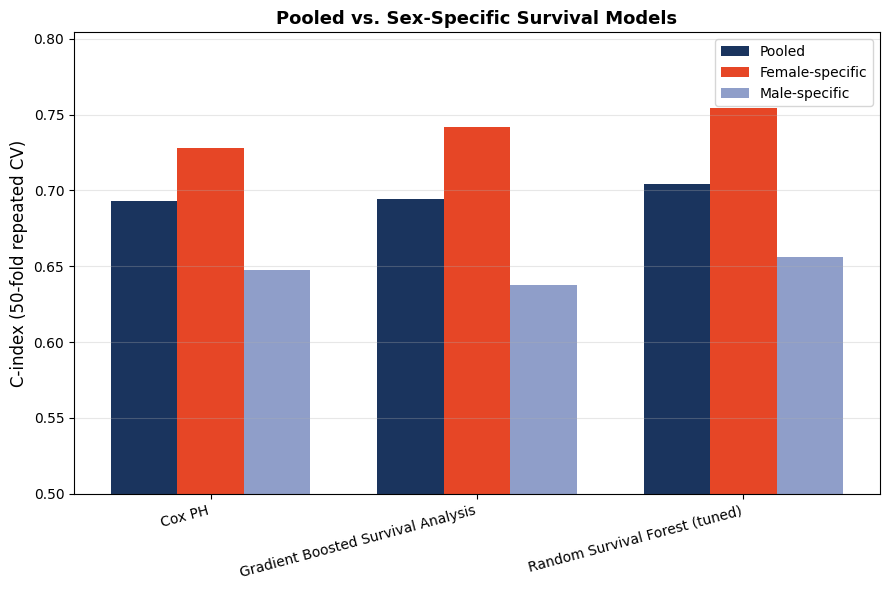

saved sex_specific_repeated_cv_survival_comparison.png


In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
models = table.index.tolist()
x = np.arange(len(models))
width = 0.25
ax.bar(x - width, table['Pooled'], width, color=USYD[4], label='Pooled')
ax.bar(x, table['F'], width, color=USYD[0], label='Female-specific')
ax.bar(x + width, table['M'], width, color=USYD[3], label='Male-specific')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.set_ylabel('C-index (50-fold repeated CV)', fontsize=12)
ax.set_title('Pooled vs. Sex-Specific Survival Models', fontsize=13, fontweight='bold')
ax.set_ylim(0.5, max(table[['Pooled','F','M']].max()) + 0.05)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('sex_specific_repeated_cv_survival_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved sex_specific_repeated_cv_survival_comparison.png')